# Locomizer signals: one weekday in Munich

Exploration of the raw Locomizer GPS signals for Germany on a single weekday, nationally and for Munich.

**How to run**

1. Extract the day once with the notebook `extract_day.ipynb` (reads ~112 GiB from Allas, ~20–30 min on 16 cores, ~10–36 BU).
   The result lands in `/scratch/project_2022768/<user>/locomizer/DEU_signals_2024-05-15/`.
2. Open this notebook in Jupyter at <https://www.roihu.csc.fi> (project `project_2022768`, a few cores and ~16 GB memory are enough)
   with the `python-geo` module as kernel and run all cells.
3. `SAMPLE = True` switches to a 1-file sample (~1/465 of the day) that is also in scratch, for quick tests.

Default day: **Wednesday 2024-05-15**, a normal working day in Bavaria (no holiday; Ascension was 9 May, Whit Monday 20 May, Corpus Christi 30 May).

In [1]:
import os, shutil, subprocess, urllib.request
from pathlib import Path

import duckdb, h3, geopandas as gpd, pandas as pd, numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from shapely.geometry import Polygon

# ---- parameters -------------------------------------------------------------
COUNTRY = "DEU"
DATE    = "2024-05-15"          # YYYY-MM-DD, must match a day extracted with extract_day.ipynb
SAMPLE  = False                 # True = 1-file sample (instant); False = full-day extract

H3_RES = 9                      # resolution of the `gid` column in the data
MIN_SIGNALS_ACTIVE = 5          # threshold for an "active" user in an area

# ---- where the data lives ---------------------------------------------------
# Allas access goes through the rclone remotes created by `allas-conf -m S3 <project>`; nothing here touches credentials.
COUNTRIES = {
    "DEU": {"project": "project_2014316", "bucket": "profile_signals_DEU", "prefix": "profile_signals_DEU"},
    "GBR": {"project": "project_2014314", "bucket": "profile_signals_GBR", "prefix": "profile_signals_GBR"},
}
SCRATCH = Path(f"/scratch/project_2022768/{os.environ['USER']}/locomizer")
RCLONE  = shutil.which("rclone") or "/appl/soft/manual/general/x86_64/allas-tools/bin/rclone"   # from `module load allas`

def remote_path(country, dataset="signals_md5", month=None):
    c = COUNTRIES[country]
    p = f"s3allas-{c['project']}:{c['bucket']}/{c['prefix']}/{dataset}"
    return f"{p}/{month}" if month else p

def list_parts(country, month, dataset="signals_md5"):
    """[(filename, bytes), ...] for one month of a dataset (read-only listing)."""
    res = subprocess.run([RCLONE, "ls", remote_path(country, dataset, month)], capture_output=True, text=True)
    if res.returncode != 0:
        raise RuntimeError(res.stderr)
    return sorted((name.strip(), int(size)) for size, name in (l.split(maxsplit=1) for l in res.stdout.splitlines()))

# ---- official boundaries: Eurostat / GISCO Urban Audit 2021 (city = municipality, FUA = functional urban area) ----
URAU_URL  = "https://gisco-services.ec.europa.eu/distribution/v2/urau/geojson/"
CITY_CODE, FUA_CODE = "DE003C", "DE003F"      # München city, FUA München
def urau_layer(layer):
    f = SCRATCH / "boundaries" / f"URAU_RG_100K_2021_4326_{layer}.geojson"
    if not f.exists():
        f.parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(URAU_URL + f.name, f)
    return gpd.read_file(f).set_index("URAU_CODE")
CITY  = urau_layer("CITIES").loc[CITY_CODE].geometry   # Munich city, 311 km²
METRO = urau_layer("FUA").loc[FUA_CODE].geometry       # Munich Functional Urban Area (city + commuting zone), 5,615 km²

def day_extract_dir(country, date):
    return SCRATCH / f"{country}_signals_{date}"

def day_extract_glob(country, date):
    return str(day_extract_dir(country, date) / "*.parquet")

# ---- plotting style -----------------------------------------------------------
ACCENT = "#2A6DD9"              # single hue used for all single-series charts
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e5e7eb", "grid.linewidth": 0.6,
                     "axes.axisbelow": True, "figure.dpi": 110})

## 1. What is in the bucket (read-only listing from Allas)

In [2]:
month = DATE[:7]
parts = list_parts(COUNTRY, month)
print(f"{COUNTRY} signals_md5/{month}: {len(parts)} parquet parts, {sum(s for _, s in parts)/2**30:.1f} GiB")

DEU signals_md5/2024-05: 465 parquet parts, 112.6 GiB


## 2. Load the extracted day

In [3]:
tag = DATE + ("-sample" if SAMPLE else "")
extract_dir = day_extract_dir(COUNTRY, tag)
if not extract_dir.exists() or not any(extract_dir.glob("*.parquet")):
    raise FileNotFoundError(
        f"No extract at {extract_dir}. Run extract_day.ipynb first with COUNTRY={COUNTRY!r}, MONTH={DATE[:7]!r}, DAY={int(DATE[8:])}")

con = duckdb.connect()
con.execute(f"SET threads = {int(os.environ.get('SLURM_CPUS_PER_TASK', os.cpu_count()))};")
con.execute(f"CREATE OR REPLACE VIEW day AS SELECT * FROM read_parquet('{day_extract_glob(COUNTRY, tag)}')")
con.execute("DESCRIBE day").df()

,column_name,column_type,null,key,default,extra
0,userid,VARCHAR,YES,None,None,None
1,lat,DOUBLE,YES,None,None,None
2,lon,DOUBLE,YES,None,None,None
3,timestamp,DOUBLE,YES,None,None,None
4,datetime,VARCHAR,YES,None,None,None
5,dow,BIGINT,YES,None,None,None
6,hour,BIGINT,YES,None,None,None
7,minute,BIGINT,YES,None,None,None
8,h3_9,VARCHAR,YES,None,None,None
9,h3_10,VARCHAR,YES,None,None,None


## 3. Germany, whole day

In [4]:
summary = con.execute("""
    SELECT count(*)                         AS signals,
           count(DISTINCT userid)           AS n_users,
           min(datetime) AS first_ts, max(datetime) AS last_ts,
           any_value(dow)                   AS dow_iso
    FROM day
""").df()
summary

,signals,n_users,first_ts,last_ts,dow_iso
0,42414993,1134577,2024-05-15,2024-05-15,3


In [5]:
# signals per user: how dense is the tracking?
per_user = con.execute("""
    SELECT userid, count(*) AS n,
           count(DISTINCT hour) AS hours_seen,
           count(DISTINCT h3_9) AS cells_seen
    FROM day GROUP BY userid
""").df()
per_user[["n", "hours_seen", "cells_seen"]].describe(percentiles=[.1, .25, .5, .75, .9, .99]).T

,count,mean,std,min,10%,25%,50%,75%,90%,99%,max
n,1134577.0,37.383970,41.791788,1.0,4.0,9.0,24.0,51.0,86.0,198.0,697.0
hours_seen,1134577.0,10.136345,6.945452,1.0,2.0,4.0,9.0,16.0,21.0,24.0,24.0
cells_seen,1134577.0,9.757293,19.186829,1.0,1.0,2.0,3.0,9.0,24.0,98.0,479.0


In [6]:
# how many users would survive a minimum-signals filter?
thresholds = [1, 2, 5, 10, 20, 50, 100]
pd.DataFrame({"min_signals": thresholds,
              "n_users": [(per_user.n >= t).sum() for t in thresholds],
              "share": [round((per_user.n >= t).mean(), 3) for t in thresholds]})

,min_signals,n_users,share
0,1,1134577,1.000
1,2,1127993,0.994
2,5,1005960,0.887
3,10,847749,0.747
4,20,632600,0.558
5,50,298589,0.263
6,100,80215,0.071


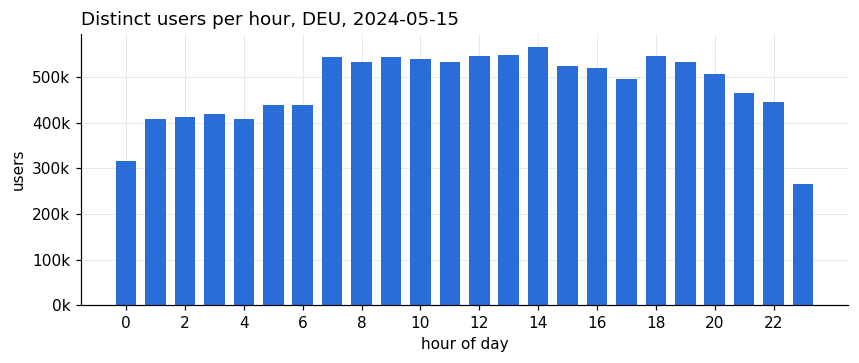

In [7]:
by_hour = con.execute("""
    SELECT hour, count(*) AS signals, count(DISTINCT userid) AS n_users
    FROM day GROUP BY hour ORDER BY hour
""").df()

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.bar(by_hour.hour, by_hour.n_users, color=ACCENT, width=0.7)
ax.set_title(f"Distinct users per hour, {COUNTRY}, {DATE}", loc="left")
ax.set_xlabel("hour of day"); ax.set_ylabel("users"); ax.set_xticks(range(0, 24, 2))
ax.yaxis.set_major_formatter(lambda v, _: f"{v/1e6:.1f}M" if v >= 1e6 else f"{v/1e3:.0f}k")
plt.show()

In [8]:
con.execute("""
    SELECT track_type, count(*) AS signals, count(DISTINCT userid) AS n_users,
           round(100.0 * count(*) / sum(count(*)) OVER (), 1) AS pct_signals
    FROM day GROUP BY track_type ORDER BY signals DESC
""").df()

,track_type,signals,n_users,pct_signals
0,pedestrian,14153295,951226,33.4
1,stop,14116802,947012,33.3
2,cars_highway,7714049,376124,18.2
3,cars_city,4320874,486289,10.2
4,cyclist,2109973,529669,5.0


## 4. Munich

`city` is the Eurostat Urban Audit city of München (the municipality) and `metro` the Munich Functional Urban Area (city plus commuting zone).
Areas are converted to the set of H3 resolution-9 cells they cover, then signals are matched on the `gid` (`h3_9`) column.
This is exact at cell level (~0.1 km² cells) and much faster than point-in-polygon on tens of millions of rows.

In [9]:
def cells_for(geom, res=H3_RES):
    return list(h3.geo_to_cells(geom, res))

cells_city  = cells_for(CITY)
cells_metro = cells_for(METRO)
print(f"city: {len(cells_city):,} H3 cells (~{len(cells_city)*0.105:.0f} km²); "
      f"metro: {len(cells_metro):,} cells (~{len(cells_metro)*0.105:.0f} km²)")

area_df = pd.DataFrame({"h3_9": cells_city + cells_metro,
                        "area": ["city"] * len(cells_city) + ["metro"] * len(cells_metro)})
con.register("area_df", area_df)
con.execute("CREATE OR REPLACE TABLE area_cells AS SELECT * FROM area_df")

con.execute("""
    CREATE OR REPLACE VIEW munich AS
    SELECT d.*, a.area
    FROM day d JOIN area_cells a USING (h3_9)
""")

city: 3,055 H3 cells (~321 km²); metro: 55,142 cells (~5790 km²)


In [10]:
# users and signals per area ('metro' contains 'city')
munich_summary = con.execute(f"""
    WITH per_user AS (
        SELECT area, userid, count(*) AS n FROM munich GROUP BY area, userid
    )
    SELECT area,
           sum(n)                                       AS signals,
           count(*)                                     AS n_users,
           count(*) FILTER (WHERE n >= {MIN_SIGNALS_ACTIVE}) AS n_users_active,
           round(median(n), 1)                          AS median_signals_per_user
    FROM per_user GROUP BY area ORDER BY area DESC
""").df()
munich_summary

,area,signals,n_users,n_users_active,median_signals_per_user
0,metro,1486016.0,48274,39732,18.0
1,city,809201.0,32153,24902,14.0


In [11]:
# how much of a Munich user's day is actually spent in the metro area?
share = con.execute("""
    WITH tot AS (SELECT userid, count(*) AS n_all FROM day GROUP BY userid),
         met AS (SELECT userid, count(*) AS n_metro FROM munich WHERE area = 'metro' GROUP BY userid)
    SELECT n_metro * 1.0 / n_all AS share_in_metro FROM met JOIN tot USING (userid)
""").df()
print(f"users with any signal in metro: {len(share):,}")
print(f"  all of their signals in metro : {(share.share_in_metro == 1).mean():.1%}")
print(f"  >= 80% of signals in metro    : {(share.share_in_metro >= .8).mean():.1%}")
print(f"  < 20% (passing through)       : {(share.share_in_metro < .2).mean():.1%}")

users with any signal in metro: 48,274
  all of their signals in metro : 77.8%
  >= 80% of signals in metro    : 81.7%
  < 20% (passing through)       : 5.3%


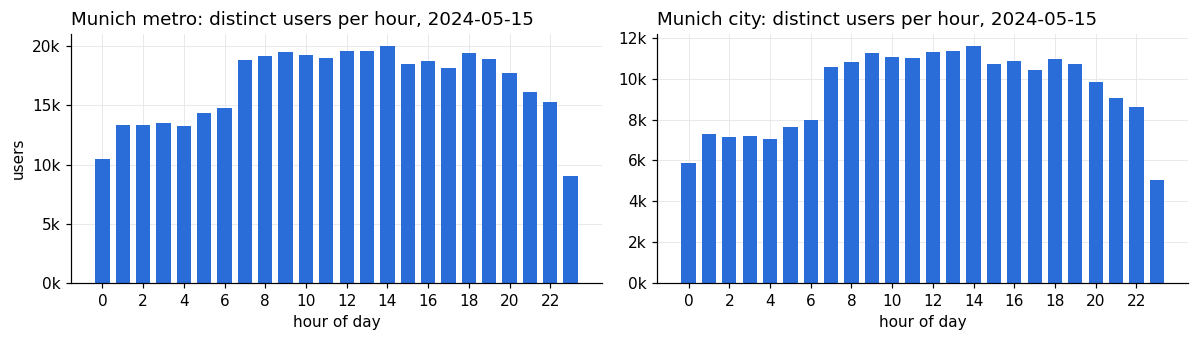

In [12]:
m_hour = con.execute("""
    SELECT area, hour, count(DISTINCT userid) AS n_users
    FROM munich GROUP BY area, hour ORDER BY area, hour
""").df()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
for ax, area in zip(axes, ["metro", "city"]):
    d = m_hour[m_hour.area == area]
    ax.bar(d.hour, d.n_users, color=ACCENT, width=0.7)
    ax.set_title(f"Munich {area}: distinct users per hour, {DATE}", loc="left")
    ax.set_xlabel("hour of day"); ax.set_xticks(range(0, 24, 2))
    ax.yaxis.set_major_formatter(lambda v, _: f"{v/1e3:.0f}k")
axes[0].set_ylabel("users")
plt.tight_layout(); plt.show()

In [13]:
con.execute("""
    SELECT area, track_type, count(*) AS signals, count(DISTINCT userid) AS n_users
    FROM munich GROUP BY area, track_type ORDER BY area DESC, signals DESC
""").df().pivot(index="track_type", columns="area", values=["signals", "n_users"]).fillna(0).astype(int)

signals         n_users       
area            city   metro    city  metro
track_type                                 
cars_city      99549  163399   13010  20316
cars_highway  118296  282825   10941  17639
cyclist        45134   76548   13263  20719
pedestrian    292427  490145   24016  36952
stop          253795  473099   21199  35425

## 5. Where in Munich: users per H3 cell

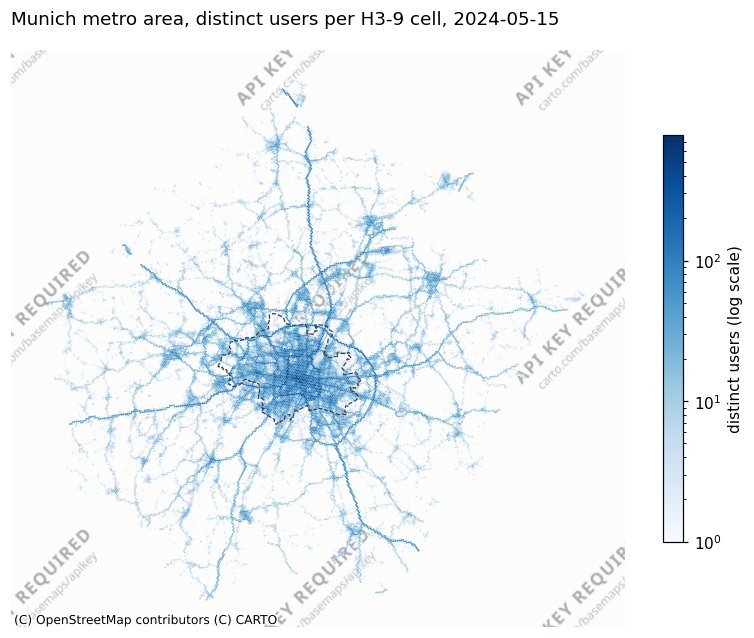

In [14]:
cell_users = con.execute("""
    SELECT h3_9, count(DISTINCT userid) AS n_users, count(*) AS signals
    FROM munich WHERE area = 'metro' GROUP BY h3_9
""").df()

cell_users["geometry"] = [Polygon([(lng, lat) for lat, lng in h3.cell_to_boundary(c)]) for c in cell_users.h3_9]
gcells = gpd.GeoDataFrame(cell_users, geometry="geometry", crs=4326).to_crs(3857)
city_outline = gpd.GeoSeries([CITY], crs=4326).to_crs(3857)

fig, ax = plt.subplots(figsize=(9, 8))
gcells.plot(column="n_users", cmap="Blues", norm=LogNorm(vmin=1, vmax=gcells.n_users.max()),
            linewidth=0, ax=ax, legend=True, legend_kwds={"label": "distinct users (log scale)", "shrink": 0.6})
city_outline.boundary.plot(ax=ax, color="#374151", linewidth=0.8, linestyle="--")
try:
    import contextily as cx
    cx.add_basemap(ax, source=cx.providers.CartoDB.PositronNoLabels, alpha=0.6)
except Exception as e:   # compute nodes may have no internet access for tiles
    print("basemap skipped:", type(e).__name__)
ax.set_axis_off(); ax.set_title(f"Munich metro area, distinct users per H3-{H3_RES} cell, {DATE}", loc="left")
plt.show()

In [15]:
# busiest cells by distinct users (sanity check: Hauptbahnhof, Marienplatz, airport, ...)
busiest = cell_users.nlargest(10, "n_users").copy()
busiest["lat"], busiest["lon"] = zip(*[h3.cell_to_latlng(c) for c in busiest.h3_9])
busiest[["h3_9", "n_users", "signals", "lat", "lon"]]

,h3_9,n_users,signals,lat,lon
8181,891f8d44a47ffff,779,2596,48.141443,11.559372
4085,891f8d7a49bffff,760,3077,48.137336,11.573976
5451,891f8d44a63ffff,621,1735,48.139390,11.566674
17401,891f8d44a7bffff,555,1890,48.139028,11.561965
18818,891f8d45d77ffff,555,1671,48.139629,11.535826
20117,891f8d7a4d3ffff,494,1790,48.134196,11.567150
14763,891f8d7a633ffff,492,1675,48.111362,11.576352
121,891f8d45d07ffff,483,1613,48.144822,11.535348
9504,891f8d44a4fffff,482,1740,48.138665,11.557255
12117,891f8d7a58fffff,455,1820,48.137807,11.614250


## Notes for the next steps

- `userid` is a string hash in the signals and parametric tables but an **int64** in `profiling_md5`, so joins to profiling need a lookup, not a cast.
- `parametric_score/<month>/LocoResidents` and `LocoWorkers_2` map users to an H3-10 home or work cell; filtering those to the Munich cells gives a resident or worker panel to compare against the daily presence counts above.
- To compare countries, run `extract_day.ipynb` with `COUNTRY = "GBR"` (about five times the data) and change `COUNTRY`.